In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../../data")

pax = pd.read_csv(DATA_DIR / "AA_PAX_FORECASTING.csv")
airport = pd.read_csv(DATA_DIR / "AA_AIRPORT_INFO.csv")

df = pax
TARGET = "OD_PAX"

In [4]:
df.shape

(1533522, 8)

In [5]:
df.columns.tolist()

['Unnamed: 0',
 'DEP_MONTH',
 'DEP_YEAR',
 'ORG_AIRPRT',
 'DES_AIRPRT',
 'OD_PAX',
 'OD_REV_USD',
 'SF_LOAD_TMS']

In [6]:
df.dtypes

Unnamed: 0       int64
DEP_MONTH        int64
DEP_YEAR         int64
ORG_AIRPRT         str
DES_AIRPRT         str
OD_PAX         float64
OD_REV_USD     float64
SF_LOAD_TMS        str
dtype: object

In [7]:
df.isna().sum()

Unnamed: 0     0
DEP_MONTH      0
DEP_YEAR       0
ORG_AIRPRT     0
DES_AIRPRT     0
OD_PAX         0
OD_REV_USD     0
SF_LOAD_TMS    0
dtype: int64

In [8]:
df[TARGET].describe()

count    1.533522e+06
mean     2.765159e+03
std      6.667135e+03
min      1.300000e-01
25%      1.292600e+02
50%      5.026550e+02
75%      2.104030e+03
max      1.401943e+05
Name: OD_PAX, dtype: float64

In [9]:
df[TARGET].skew()

np.float64(5.324332472610794)

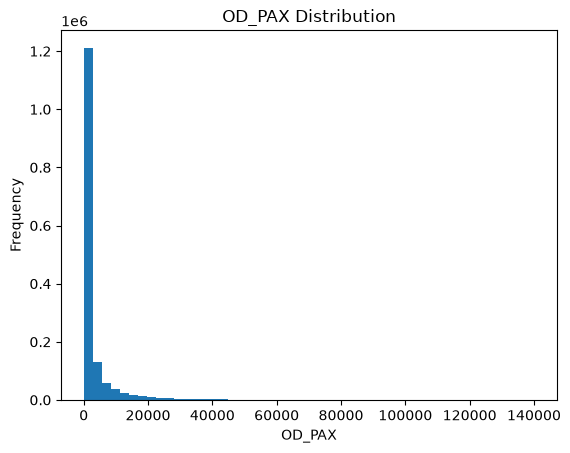

In [10]:
plt.hist(df[TARGET].dropna(), bins=50)
plt.xlabel("OD_PAX")
plt.ylabel("Frequency")
plt.title("OD_PAX Distribution")
plt.show()

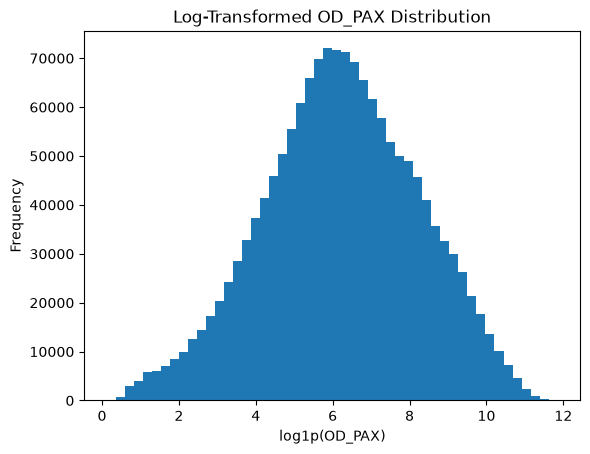

In [11]:
plt.hist(np.log1p(df[TARGET].dropna()), bins=50)
plt.xlabel("log1p(OD_PAX)")
plt.ylabel("Frequency")
plt.title("Log-Transformed OD_PAX Distribution")
plt.show()

C:\Users\adcha\AppData\Local\Temp\ipykernel_43564\738136816.py:1: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[TARGET].dropna(), vert=False)


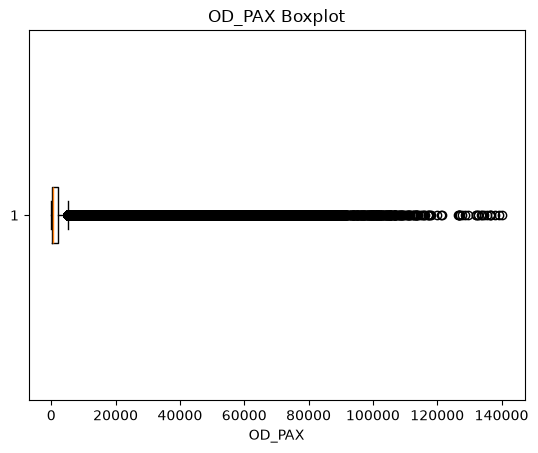

In [12]:
plt.boxplot(df[TARGET].dropna(), vert=False)
plt.xlabel("OD_PAX")
plt.title("OD_PAX Boxplot")
plt.show()

OD_PAX is strongly right-skewed in its original form, while the log-transformed target is much more symmetric and approximately bell-shaped. Therefore, I recommend modeling log1p(OD_PAX) rather than the raw target. This should reduce the influence of the highest-demand routes while preserving those observations instead of deleting them as outliers.

In [14]:
df.groupby(["ORG_AIRPRT", "DES_AIRPRT"])[TARGET].agg(
    ["count", "mean", "median", "max"]
).sort_values("max", ascending=False).head(20)

,,count,mean,median,max
ORG_AIRPRT,DES_AIRPRT,,,,
JFK,LAX,91,92238.589121,100145.12,140194.27
LAX,JFK,91,92085.860989,100057.18,136606.80
LGA,ORD,91,71440.837033,78701.73,126796.33
ORD,LGA,91,71233.787473,79304.90,126559.88
SFO,LAX,91,70314.801868,78034.91,108387.26
LAX,SFO,91,70293.838242,78236.37,108058.46
LHR,JFK,91,60168.009670,71349.70,107243.40
JFK,LHR,91,60584.814066,72292.84,100651.39
EWR,MCO,91,69067.095165,73862.88,95147.21


In [15]:
q1 = df[TARGET].quantile(0.25)
q3 = df[TARGET].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_mask = (df[TARGET] < lower) | (df[TARGET] > upper)

print("Potential outliers:", outlier_mask.sum())

Potential outliers: 208857


The target contains high-end statistical outliers, but these should not be removed automatically. Passenger demand naturally varies substantially across routes, and high values may represent legitimate high-volume airport pairs rather than bad data. Therefore, extreme OD_PAX observations should be retained unless there is clear evidence that they are erroneous or corrupted.

Because OD_PAX is strongly right-skewed while log1p(OD_PAX) is much more symmetric, I recommend training the model on log1p(OD_PAX) using squared-error loss. This reduces the influence of extremely high-demand routes without removing valid observations. Predictions can later be converted back to the original passenger-count scale using expm1. Raw-target squared error can be used as a baseline, while MAE or Huber loss could be tested as more robust alternatives.

y_log = np.log1p(df[TARGET])

print("Raw skew:", df[TARGET].skew())
print("Log skew:", y_log.skew())

In [17]:
df.isna().sum()

Unnamed: 0     0
DEP_MONTH      0
DEP_YEAR       0
ORG_AIRPRT     0
DES_AIRPRT     0
OD_PAX         0
OD_REV_USD     0
SF_LOAD_TMS    0
dtype: int64

In [19]:
(df.isna().mean() * 100).sort_values(ascending=False)

Unnamed: 0     0.0
DEP_MONTH      0.0
DEP_YEAR       0.0
ORG_AIRPRT     0.0
DES_AIRPRT     0.0
OD_PAX         0.0
OD_REV_USD     0.0
SF_LOAD_TMS    0.0
dtype: float64

The main passenger dataset contains no missing values in the observed columns. Therefore, no imputation is needed for the core passenger-modeling table. Missingness in the separate airport reference table should be handled independently based on what each airport metadata field represents.

OD_REV_USD is a likely leakage feature because realized revenue would only be known after passenger demand has occurred. Therefore, it should not be used to predict OD_PAX. The Unnamed: 0 column is an index artifact and should also be dropped. SF_LOAD_TMS should not be used until its meaning and availability at prediction time are confirmed.

In [20]:
df.columns.tolist()

['Unnamed: 0',
 'DEP_MONTH',
 'DEP_YEAR',
 'ORG_AIRPRT',
 'DES_AIRPRT',
 'OD_PAX',
 'OD_REV_USD',
 'SF_LOAD_TMS']

In [21]:
df.select_dtypes(include=np.number).corr()[TARGET].sort_values(ascending=False)

OD_PAX        1.000000
OD_REV_USD    0.759348
DEP_YEAR      0.049824
Unnamed: 0    0.022255
DEP_MONTH     0.014381
Name: OD_PAX, dtype: float64

In [22]:
print("Origin airports:", df["ORG_AIRPRT"].nunique())
print("Destination airports:", df["DES_AIRPRT"].nunique())

Origin airports: 150
Destination airports: 150


The EDA points toward a gradient-boosted tree model such as XGBoost or LightGBM. The dataset contains high-cardinality airport categories, seasonal effects, and likely nonlinear relationships between route, time, and passenger demand. These characteristics are better suited to boosted trees than to a simple linear model.

| Column / feature | Decision | Reason |
|---|---|---|
| OD_PAX | target | Passenger demand is the quantity being predicted |
| log1p(OD_PAX) | engineer | Reduces right skew and limits the influence of extreme values |
| Extreme OD_PAX values | keep | High-demand routes can legitimately have large passenger counts |
| OD_REV_USD | leak / drop | Realized revenue would not be appropriate information at prediction time |
| Unnamed: 0 | drop / id | Index artifact with no predictive meaning |
| ORG_AIRPRT | keep | Origin airport is important route information |
| DES_AIRPRT | keep | Destination airport is important route information |
| DEP_MONTH | engineer | Captures seasonality |
| DEP_YEAR | keep | Captures changes over time |
| SF_LOAD_TMS | review / likely drop | Meaning and availability at prediction time should be confirmed before use |